In [1]:
from em1d.experiment import *
from em1d.transforms import invLaplace
import matplotlib.pyplot as plt
import numpy as np

class ForwardLaplace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)

    def forward(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]

            def laplace_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s
                tmp_u0 = u0(omega, lmb)
                intg = torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb)*lmb**2 / tmp_u0
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                res = torch.squeeze(intg/c.fourpi)
                return res#.real
            
            cbft = invLaplace(laplace_integrand, n_coefficients=16)
            resp = cbft(self.times)
            return resp
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
        return integrate_around_loop(self.source, self.receiver, hkl1).T
        

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0

In [9]:
from em1d.transforms import hankel_coefficients
hk1 = hankel_coefficients(1, -20, 10, 10)

In [2]:
## tested performing the hankel first, followed by the invlaplace... takes way longer (~4x)

from em1d.experiment import *
from em1d.transforms import invLaplace
import matplotlib.pyplot as plt
import numpy as np

class ForwardLaplace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)

    def forward(self):
        
        def laplace_integrand(s):
            omega = -1j*s[None, :, None]
            def wvlngth_integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)

                intg = torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb)*lmb**2 / tmp_u0

                if self.waveform is not None:
                    intg /= -1j*omega

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                res = torch.squeeze(intg/c.fourpi)
                return res
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
            return integrate_around_loop(self.source, self.receiver, hkl1)            
        cbft = invLaplace(laplace_integrand, n_coefficients=8)
        resp = cbft(self.times)
        return resp.T

        

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0
    
# %%timeit
# dbdt2 = fwr2(sigma, thick)

In [6]:
## tested performing the hankel first, followed by the invlaplace... takes way longer (~4x)

from em1d.experiment import *
from em1d.transforms import invLaplace
from em1d.physics import halfspace_horizontal_electric_dipole
import matplotlib.pyplot as plt
import numpy as np


class ForwardLaplaceHalfspace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)

    def forward(self):
        
        def laplace_integrand(s):
            omega = -1j*s[None, :, None]
            def hofr(r):
                return halfspace_horizontal_electric_dipole(self.sigma, omega, r)
            return integrate_around_loop(self.source, self.receiver, hofr).squeeze()
        cbft = invLaplace(laplace_integrand, n_coefficients=8)
        resp = cbft(self.times)
        return resp.T       

    def __call__(self, sigma, thick):
        self.sigma = torch.tensor(sigma, dtype=torch.complex128, device=self.device)
        return self.forward().real*c.mu0
    
# %%timeit
# dbdt2 = fwr2(sigma, thick)

In [7]:
wv = Waveform.example()
lp = Loop.square(3)
t = torch.logspace(-7, -3, 31)
rx = Receiver(x=9)
fwr1 = Forward(lp, rx, t)#, waveform=wv)
fwr2 = ForwardLaplaceHalfspace(lp, rx, t)#, waveform=wv)

C:\Users\au646858\AppData\Local\Temp\ipykernel_18848\3166012408.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)


In [8]:
dbdt1 = fwr2(1./40., None)

RuntimeError: dot : expected both vectors to have same dtype, but found ComplexFloat and ComplexDouble

In [18]:

nf = 10
sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10, 25, 0.2, 0.5, 10, 15, 20])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
thick = torch.tensor([40, 40, 40, 40, 40, 40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

dbdt1 = fwr1(sigma, thick)
dbdt2 = fwr2(sigma, thick)

C:\Users\au646858\AppData\Local\Temp\ipykernel_26344\3279090442.py:57: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma[:1,:])


RuntimeError: size mismatch, got input (8), mat (8x10), vec (8)

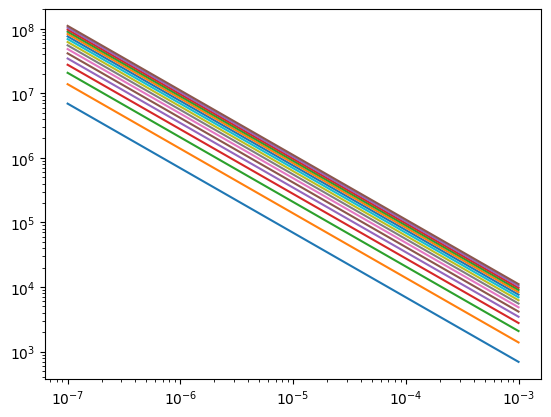

In [25]:
plt.figure()
plt.loglog(fwr1.times.numpy(), np.arange(1, 17)[None,:]*c.log2/fwr1.times.numpy()[:, None])

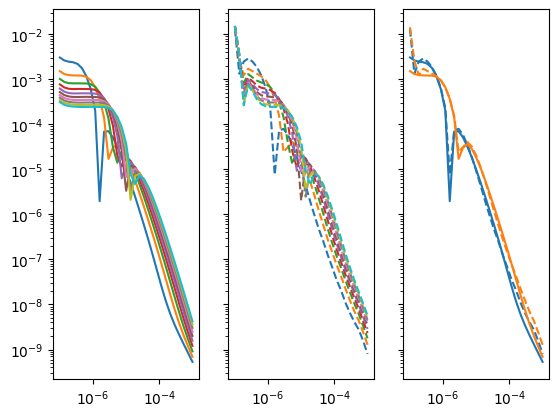

In [20]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True)
axs[0].loglog(fwr1.times.numpy(), np.abs(dbdt1.real.numpy().T))
axs[1].loglog(fwr1.times.numpy(), np.abs(dbdt2.real.numpy()).T, '--')
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt1.real[0].numpy()))
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt2.real[0].numpy()), 'C0--')

axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt1.real[1].numpy()))
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt2.real[1].numpy()), 'C1--')

True


c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


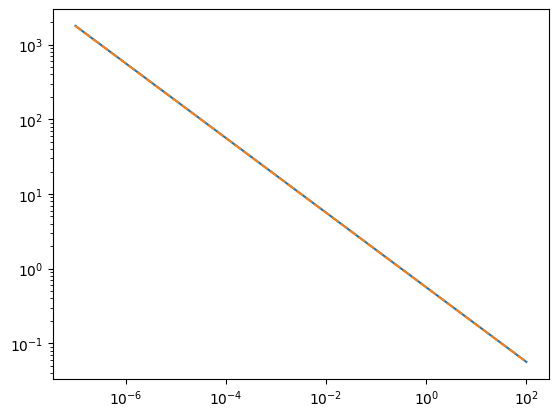

In [21]:
def f(t):
    return 1./torch.sqrt(torch.pi*t)

def LF(s):
    return 1./torch.sqrt(s)

t = torch.logspace(-7, 2, 31, dtype=torch.complex128)

f_est = invLaplace(LF, n_coefficients=16)(t)
f_act = f(t)

print(torch.allclose(f_est.real, f_act.real))

plt.figure()
plt.loglog(t.numpy(), f_est.numpy())
plt.loglog(t.numpy(), f_act.numpy(), '--')